In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
plt.rcParams["axes.grid"] = True
RANDOM_STATE = 42

df = pd.read_csv("sample_data/student-por.csv", sep=";")
print("Размер таблицы:", df.shape)
print("Столбцы:", df.columns.tolist())
display(df)

Размер таблицы: (649, 33)
Столбцы: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,course,mother,1,3,1,no,no,no,yes,no,yes,yes,no,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,course,mother,1,2,0,no,yes,no,no,yes,yes,yes,no,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,course,mother,2,2,0,no,no,no,yes,yes,yes,no,no,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,6,10,10,10


In [2]:
target = "G3"
excluded = ["G1", "G2"]

numeric_features = [
    c for c in df.select_dtypes(include=["int64", "float64"]).columns
    if c not in excluded + [target]
]

categorical_features = [
    c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
    if c not in excluded + [target]
]

print(f"Цель: {target}")
print(f"Исключены: {excluded}")
print(f"Числовые ({len(numeric_features)} штук): {numeric_features}")
print(f"Категориальные ({len(categorical_features)} штук): {categorical_features}")

all_features = set(df.columns) - set(excluded) - {target}
classified = set(numeric_features) | set(categorical_features)
print(all_features == classified)  # Проверка

Цель: G3
Исключены: ['G1', 'G2']
Числовые (13 штук): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Категориальные (17 штук): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
True


Проверка качества данных

In [3]:
print(df.shape)
print("\n Информация общая")
df.info()
print("\n")
display(df.describe(include="all").T)
print("\n")
display(df.isna().sum().to_frame("missing_count"))
print("\n")
print("Количество дубликатов:", df.duplicated().sum())

(649, 33)

 Информация общая
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0




Количество дубликатов: 0


Пропусков нет, Дубликатов тоже

In [4]:
print(f"G3: min={df['G3'].min()}, max={df['G3'].max()}")

G3: min=0, max=19


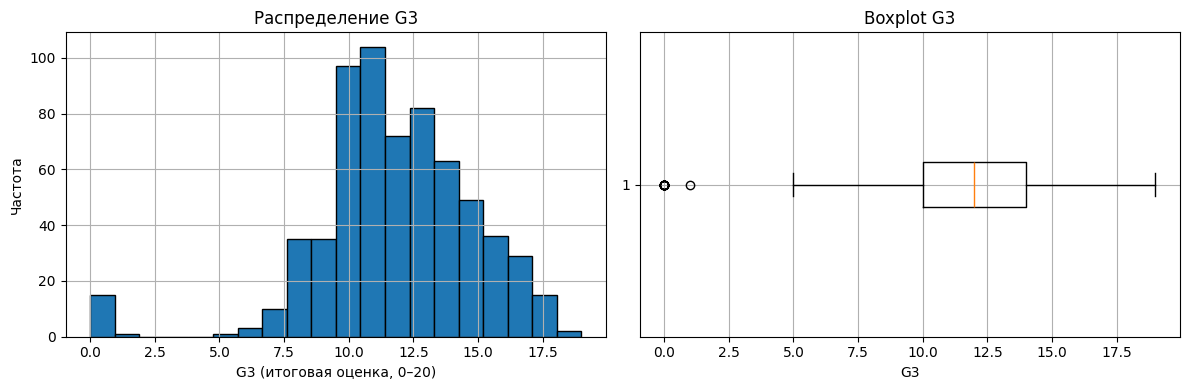

Статистика G3:
count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

Асимметрия (skew): -0.913


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["G3"], bins=20, edgecolor="black")
axes[0].set_title("Распределение G3")
axes[0].set_xlabel("G3 (итоговая оценка, 0–20)")
axes[0].set_ylabel("Частота")

axes[1].boxplot(df["G3"], vert=False)
axes[1].set_title("Boxplot G3")
axes[1].set_xlabel("G3")

plt.tight_layout()
plt.show()

print("Статистика G3:")
print(df["G3"].describe())
print("\nАсимметрия (skew):", round(df["G3"].skew(), 3))

Видим, что 75 процентов учеников получили итоговую оценку более чем 10, но при этом средняя оценка держится на 12. На самом деле вполне обычное распределение, никаких аномалий здесь не видно. Стоит только обратить внимание на то, что пристутсует окло 15 учеников которые получили 0 на экзамене.

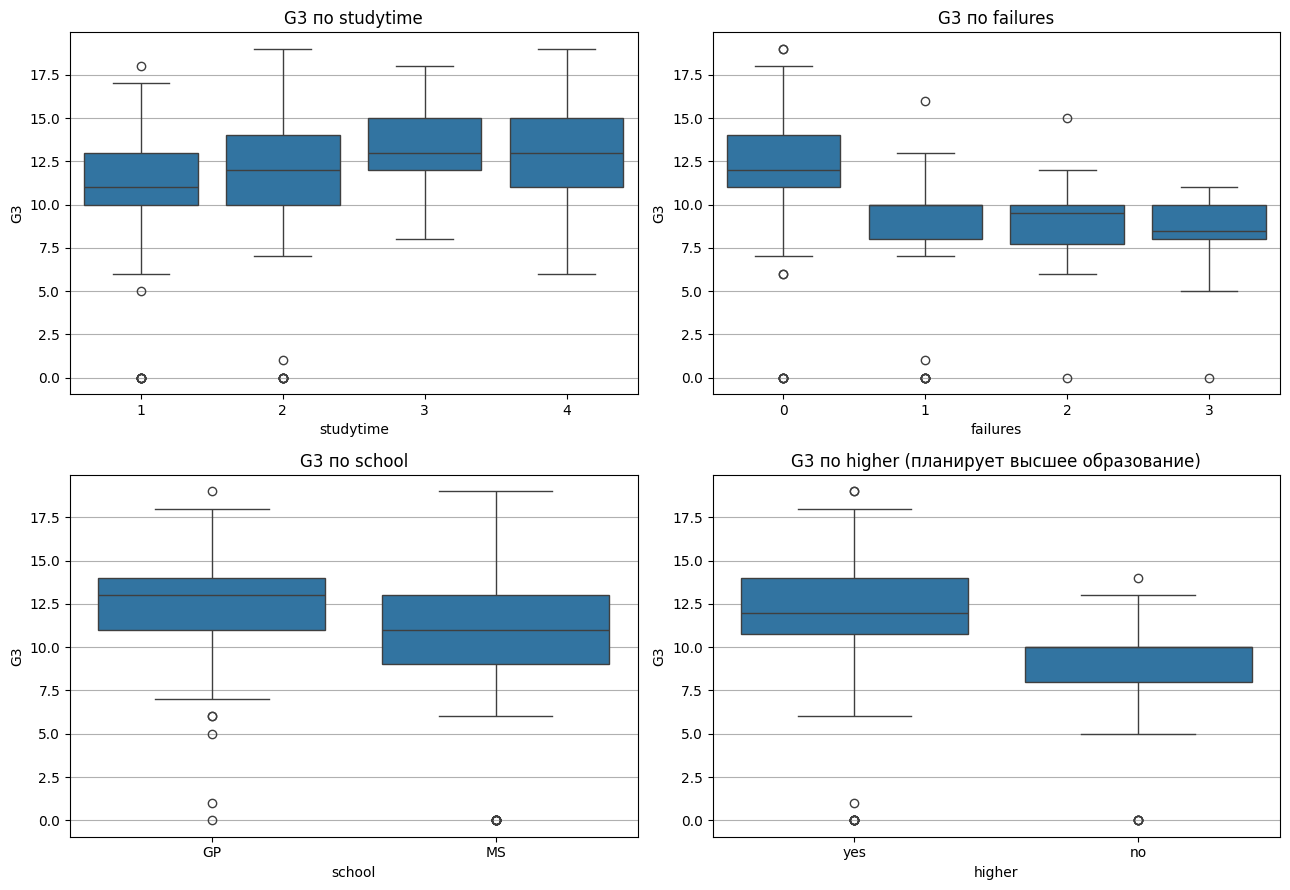

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.boxplot(data=df, x="studytime", y="G3", ax=axes[0, 0])
axes[0, 0].set_title("G3 по studytime")
axes[0, 0].set_xlabel("studytime")
axes[0, 0].set_ylabel("G3")

sns.boxplot(data=df, x="failures", y="G3", ax=axes[0, 1])
axes[0, 1].set_title("G3 по failures")
axes[0, 1].set_xlabel("failures")
axes[0, 1].set_ylabel("G3")

sns.boxplot(data=df, x="school", y="G3", ax=axes[1, 0])
axes[1, 0].set_title("G3 по school")
axes[1, 0].set_xlabel("school")
axes[1, 0].set_ylabel("G3")

sns.boxplot(data=df, x="higher", y="G3", ax=axes[1, 1])
axes[1, 1].set_title("G3 по higher (планирует высшее образование)")
axes[1, 1].set_xlabel("higher")
axes[1, 1].set_ylabel("G3")

plt.tight_layout()
plt.show()

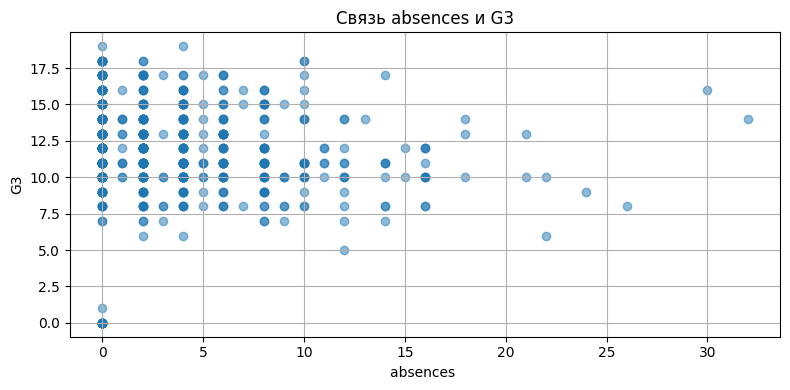

Средний G3 по studytime:


,mean,median,count
studytime,,,
1,10.84,11.0,212
2,12.09,12.0,305
3,13.23,13.0,97
4,13.06,13.0,35


Средний G3 по failures:


,mean,median,count
failures,,,
0,12.51,12.0,549
1,8.64,10.0,70
2,8.81,9.5,16
3,8.07,8.5,14


Средний G3 по school:


,mean,median,count
school,,,
GP,12.58,13.0,423
MS,10.65,11.0,226


Средний G3 по higher:


,mean,median,count
higher,,,
no,8.80,10.0,69
yes,12.28,12.0,580


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df["absences"], df["G3"], alpha=0.5)
ax.set_xlabel("absences ")
ax.set_ylabel("G3")
ax.set_title("Связь absences и G3")
plt.tight_layout()
plt.show()

print("Средний G3 по studytime:")
display(df.groupby("studytime")["G3"].agg(["mean", "median", "count"]).round(2))

print("Средний G3 по failures:")
display(df.groupby("failures")["G3"].agg(["mean", "median", "count"]).round(2))

print("Средний G3 по school:")
display(df.groupby("school")["G3"].agg(["mean", "median", "count"]).round(2))

print("Средний G3 по higher:")
display(df.groupby("higher")["G3"].agg(["mean", "median", "count"]).round(2))

В целомм везде есть какая та коррелляция, хоть это и не прям заметно, условно видно что ученики со study_time 4, получают в среднем оценки выше, чем  ученики со study_time 1

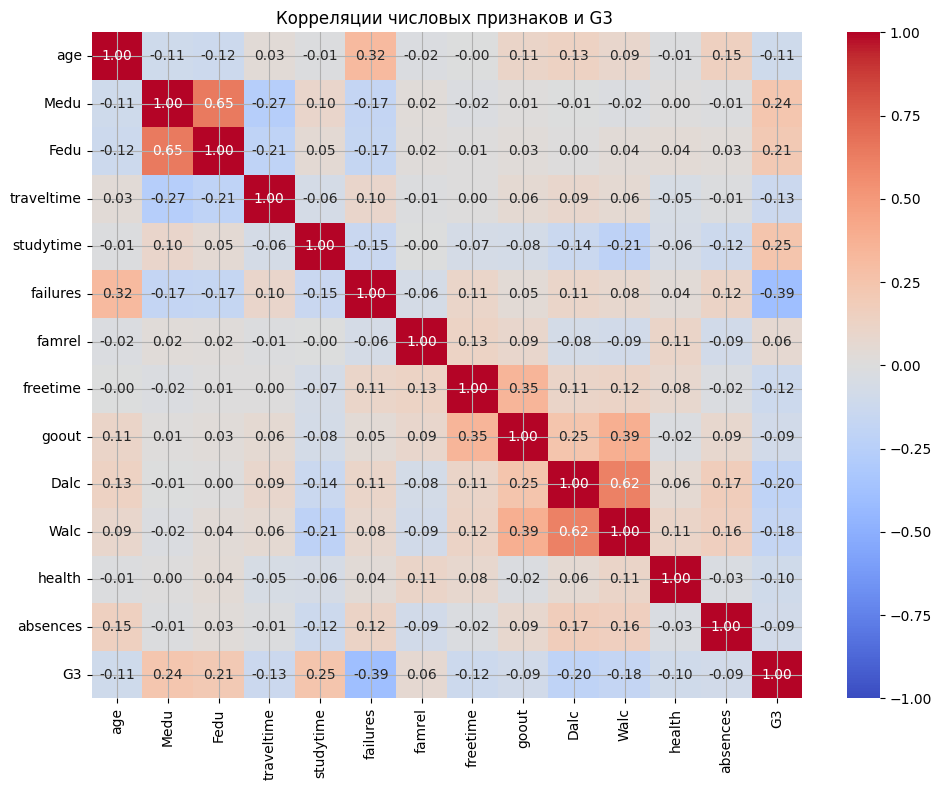

Корреляции с G3:


,correlation_with_G3
failures,-0.393
studytime,0.250
Medu,0.240
Fedu,0.212
Dalc,-0.205
Walc,-0.177
traveltime,-0.127
freetime,-0.123
age,-0.107
health,-0.099


In [8]:
corr_cols = numeric_features + [target]
corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Корреляции числовых признаков и G3 ")
plt.tight_layout()
plt.show()

print("Корреляции с G3:")
display(
    corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
    .to_frame("correlation_with_G3")
    .round(3)
)

То есть мы видим что в зависимости от failures, у нас максимальная коррелляция c G3.

In [9]:
from scipy import stats

# H1: failures говорит о более низком G3
groups1 = [df.loc[df["failures"] == k, "G3"] for k in sorted(df["failures"].unique())]
stat1, p1 = stats.kruskal(*groups1)
print(f"H1: Kruskal-Wallis H={stat1:.3f}, p={p1:}")
print(df.groupby("failures")["G3"].mean().round(2))

# H2:  G3 различается между группами со studytime
groups2 = [df.loc[df["studytime"] == k, "G3"] for k in sorted(df["studytime"].unique())]
stat2, p2 = stats.kruskal(*groups2)
print(f"\nH2 Kruskal-Wallis H={stat2:.3f}, p={p2:}")
print(df.groupby("studytime")["G3"].mean().round(2))

# H3:  absences информативный признак для g3
r, p3 = stats.pearsonr(df["absences"], df["G3"])
rho, p3s = stats.spearmanr(df["absences"], df["G3"])
print(f"\nH3:")
print(f"Pearson r={r:.3f}, p={p3:}")
print(f"Spearman rho={rho:.3f}, p={p3s}")

# Своя гипотеза
# H4: Чем выше образование матери (Medu), тем выше итоговая оценка G3
groups_medu = [df.loc[df["Medu"] == k, "G3"] for k in sorted(df["Medu"].unique())]
stat_m, p_m = stats.kruskal(*groups_medu)
print(f"\nH4 : Kruskal-Wallis H={stat_m:.3f}, p={p_m:.4e}")
print(df.groupby("Medu")["G3"].agg(["mean", "median", "count"]).round(2))

H1: Kruskal-Wallis H=130.659, p=3.8997335139424093e-28
failures
0    12.51
1     8.64
2     8.81
3     8.07
Name: G3, dtype: float64

H2 Kruskal-Wallis H=50.316, p=6.841570528918375e-11
studytime
1    10.84
2    12.09
3    13.23
4    13.06
Name: G3, dtype: float64

H3:
Pearson r=-0.091, p=0.01989562393916079
Spearman rho=-0.159, p=4.991938518202622e-05

H4 : Kruskal-Wallis H=57.215, p=1.1151e-11
       mean  median  count
Medu                      
0     11.67    11.0      6
1     10.80    11.0    143
2     11.66    12.0    186
3     11.92    12.0    139
4     13.07    13.0    175


1. Гипотеза о том, что колво прошлых неудач связано с низкой оценкой принимается
2. Гипотеза о том, что G3 различается между группами с разным стадитайм верна
3. То есть здесь видим, что связь есть, но она слабая из за |r| < 0.2
4. Здесь тоже видим, что есть связь между образованием матери и оценкой g3

Скорее всего с образованием отца будет также

## Заключение

1. Датасет 649 записей, 33 столбца не содержит пропусков
   и полных дубликатов, типы данных корректны, а целевая переменная `G3`
   распределена в диапазоне 0–20 с медианой около 12 и лёгкой левой
   асимметрией, что отражает школьную шкалу с хвостом низких оценок
2. Проверка гипотез показала, что `failures` - самый сильный из доступных
   признаков, `studytime` и образование родителей `Medu` дают слабый, но статистически значимый положительный эффект,
   `higher` заметно различает группы, а `absences` статистически значим, но
   слаб по силе
3. Ограничения данных: часть связей нелинейна, поэтому линейные корреляции могут недооценивать вклад признаков, а категориальные переменные требуют явного кодирования.
4. План подготовки к моделированию: OneHotEncoder(LabelEncoding) для категориальных и
   StandardScaler для числовых признаков внутри пайплайна, сравнение LinReg, Ridge/Lasso и RandomForest по MAE MSE RMSE через KFold-кросс-валидацию, финальная оценка на отложенных 20% , а также отдельное сравнение
   сценариев без G1/G2 и с G1/G2, чтобы показать вклад
   промежуточных оценок.

## Модели

Дальше по плану из заключения: предсказываю G. Два набора признаков будет

без G1 и G2 - то, что известно до итоговой оценки

с G1 и G2 - чтобы было видно, сколько качества мы добавим за счет  промежуточных оценок

Числовые признаки через StandardScaler, категориальные через OneHotEncoder, всё внутри пайплайна. Модели: среднее по train как планка(дамми регрессор), линейная регрессия, Ridge, Lasso и случайный лес. Сравнение на 5 фолдах по обучающим 80%. Финальные цифры смотрим на отложенных 20%, модель для графиков беру по лучшему CrossVal MAE


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ALPHAS = np.logspace(-3, 3, 25)

idx = np.arange(len(df))
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=RANDOM_STATE)
y = df[target]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

scenarios = {
    "без G1/G2": {
        "X": df.drop(columns=[target, "G1", "G2"]),
        "num": numeric_features,
        "cat": categorical_features,
    },
    "с G1/G2": {
        "X": df.drop(columns=[target]),
        "num": numeric_features + ["G1", "G2"],
        "cat": categorical_features,
    },
}


def make_models():
    return {
        "Среднее": DummyRegressor(strategy="mean"),
        "LinReg": LinearRegression(),
        "Ridge": RidgeCV(alphas=ALPHAS),
        "Lasso": LassoCV(alphas=ALPHAS, max_iter=20000, random_state=RANDOM_STATE),
        "RandomForest": RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    }


def make_pipe(num_cols, cat_cols, model):
    prep = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                cat_cols,
            ),
        ]
    )
    return Pipeline([("prep", prep), ("model", model)])


cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
fitted = {}

for scenario, spec in scenarios.items():
    X_train = spec["X"].iloc[idx_train]
    X_test = spec["X"].iloc[idx_test]
    for name, model in make_models().items():
        pipe = make_pipe(spec["num"], spec["cat"], model)
        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "rmse": "neg_root_mean_squared_error",
                "r2": "r2",
            },
        )
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        fitted[(scenario, name)] = (pipe, pred)
        rows.append(
            {
                "сценарий": scenario,
                "модель": name,
                "CV MAE": -scores["test_mae"].mean(),
                "CV RMSE": -scores["test_rmse"].mean(),
                "CV R2": scores["test_r2"].mean(),
                "test MAE": mean_absolute_error(y_test, pred),
                "test MSE": mean_squared_error(y_test, pred),
                "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                "test R2": r2_score(y_test, pred),
            }
        )

metrics = pd.DataFrame(rows)
display(metrics.round(3))
print(f"train {len(idx_train)}, test {len(idx_test)}")

for scenario in scenarios:
    for name in ("Ridge", "Lasso"):
        alpha = fitted[(scenario, name)][0].named_steps["model"].alpha_
        print(f"{scenario}, {name}: alpha={alpha:.4g}")


,сценарий,модель,CV MAE,CV RMSE,CV R2,test MAE,test MSE,test RMSE,test R2
0,без G1/G2,Среднее,2.428,3.233,-0.020,2.395,10.065,3.173,-0.032
1,без G1/G2,LinReg,2.046,2.790,0.226,2.156,8.190,2.862,0.160
2,без G1/G2,Ridge,2.011,2.761,0.248,2.051,7.757,2.785,0.205
3,без G1/G2,Lasso,2.023,2.771,0.239,2.079,7.840,2.800,0.196
4,без G1/G2,RandomForest,1.969,2.670,0.299,2.035,7.666,2.769,0.214
5,с G1/G2,Среднее,2.428,3.233,-0.020,2.395,10.065,3.173,-0.032
6,с G1/G2,LinReg,0.885,1.332,0.826,0.765,1.476,1.215,0.849
7,с G1/G2,Ridge,0.866,1.323,0.829,0.758,1.458,1.208,0.850
8,с G1/G2,Lasso,0.817,1.286,0.838,0.719,1.315,1.147,0.865
9,с G1/G2,RandomForest,0.847,1.301,0.832,0.719,1.451,1.204,0.851


train 519, test 130
без G1/G2, Ridge: alpha=56.23
без G1/G2, Lasso: alpha=0.03162
с G1/G2, Ridge: alpha=17.78
с G1/G2, Lasso: alpha=0.05623


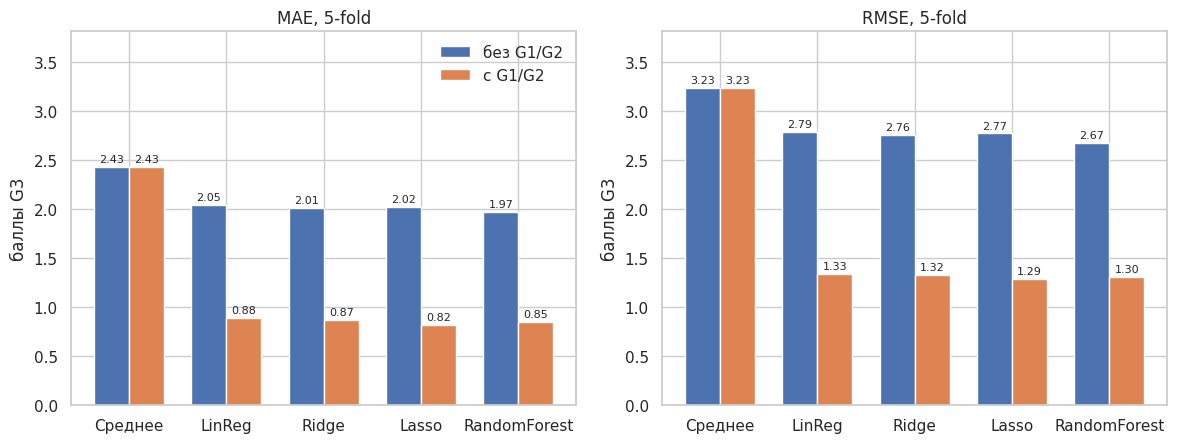

In [11]:
sns.set_theme(style="whitegrid")

model_order = ["Среднее", "LinReg", "Ridge", "Lasso", "RandomForest"]
palette = {"без G1/G2": "#4C72B0", "с G1/G2": "#DD8452"}
x = np.arange(len(model_order))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, col, title in zip(
    axes,
    ["CV MAE", "CV RMSE"],
    ["MAE, 5-fold", "RMSE, 5-fold"],
):
    for i, scenario in enumerate(["без G1/G2", "с G1/G2"]):
        part = metrics[metrics["сценарий"] == scenario].set_index("модель").loc[model_order]
        bars = ax.bar(
            x + (i - 0.5) * width,
            part[col],
            width=width,
            label=scenario,
            color=palette[scenario],
        )
        for bar in bars:
            h = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                h + 0.03,
                f"{h:.2f}",
                ha="center",
                va="bottom",
                fontsize=8,
            )
    ax.set_xticks(x, model_order)
    ax.set_ylabel("баллы G3")
    ax.set_title(title)
    ax.set_ylim(0, metrics[["CV MAE", "CV RMSE"]].to_numpy().max() * 1.18)

axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()


лучшая по CV MAE: {'без G1/G2': 'RandomForest', 'с G1/G2': 'Lasso'}


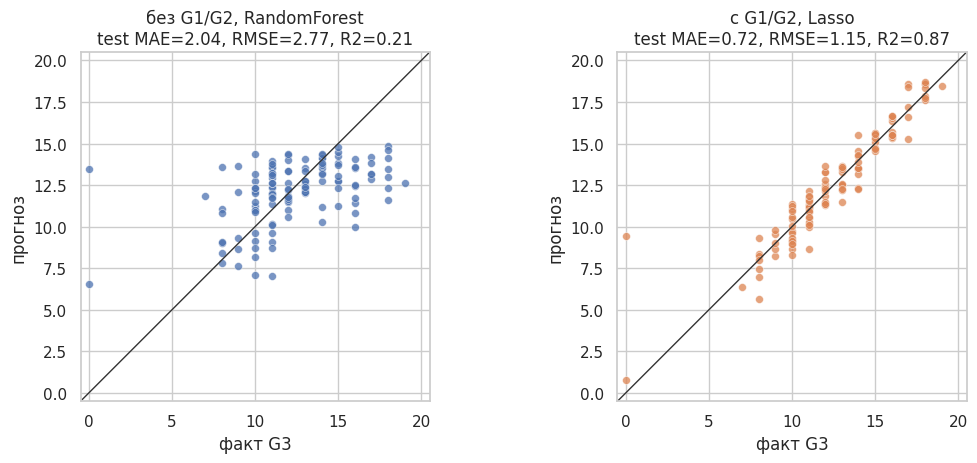

In [16]:
best_names = {}
for scenario in scenarios:
    part = metrics[metrics["сценарий"] == scenario]
    best_names[scenario] = part.loc[part["CV MAE"].idxmin(), "модель"]
print("лучшая по CV MAE:", best_names)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
lims = [-0.5, 20.5]
for ax, scenario in zip(axes, ["без G1/G2", "с G1/G2"]):
    name = best_names[scenario]
    pred = fitted[(scenario, name)][1]
    row = metrics[(metrics["сценарий"] == scenario) & (metrics["модель"] == name)].iloc[0]
    ax.scatter(
        y_test,
        pred,
        s=32,
        alpha=0.75,
        color=palette[scenario],
        edgecolor="white",
        linewidth=0.4,
    )
    ax.plot(lims, lims, color="#333333", lw=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.set_xlabel("факт G3")
    ax.set_ylabel("прогноз")
    ax.set_title(
        f"{scenario}, {name}\n"
        f"test MAE={row['test MAE']:.2f}, RMSE={row['test RMSE']:.2f}, R2={row['test R2']:.2f}"
    )
fig.tight_layout()
plt.show()


без G1/G2 RandomForest
  failures             0.2526
  absences             0.0694
  Fedu                 0.0450
  Dalc                 0.0434
  health               0.0354
  Walc                 0.0353
  Medu                 0.0319
  studytime            0.0314
  freetime             0.0308
  school_MS            0.0286
  age                  0.0283
  goout                0.0277
с G1/G2 Lasso
  G2                   2.4808
  G1                   0.4570
  school_GP            0.0758
  failures             0.0451
  absences             0.0399
  freetime             0.0377
  studytime            0.0364
  Dalc                 0.0230
  health               0.0136
  famrel               0.0091


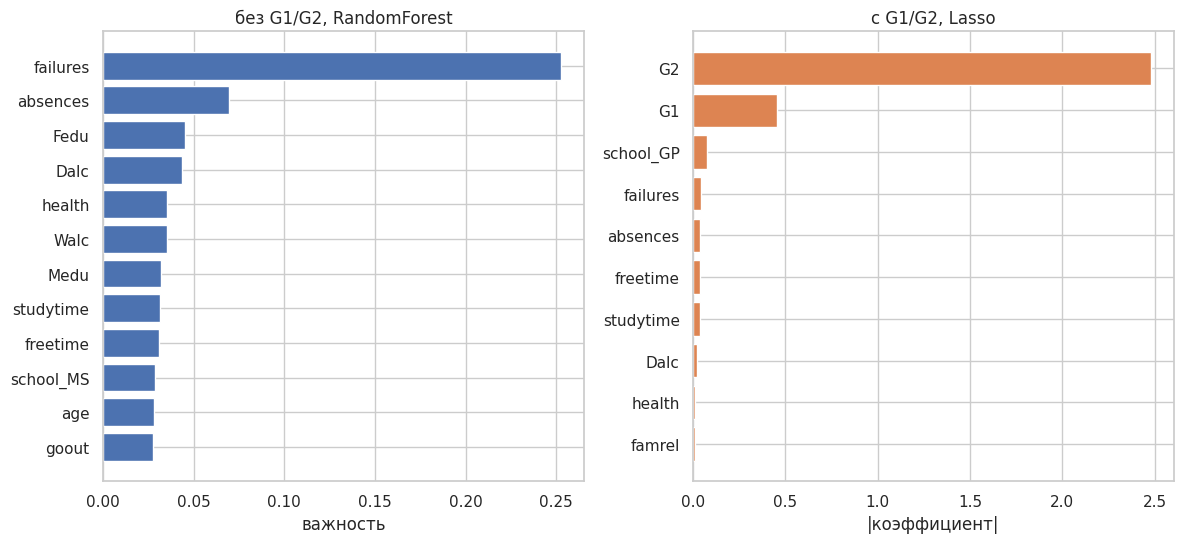

In [22]:
def top_features(pipe, k=12):
    names = np.array(
        [n.split("__", 1)[-1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    )
    model = pipe.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        values = model.feature_importances_
        kind = "важность"
    else:
        values = np.abs(model.coef_)
        kind = "|коэффициент|"
    keep = values > 1e-8
    names, values = names[keep], values[keep]
    order = np.argsort(values)[-k:]
    return list(names[order]), values[order], kind


fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, scenario in zip(axes, ["без G1/G2", "с G1/G2"]):
    name = best_names[scenario]
    labels, values, kind = top_features(fitted[(scenario, name)][0])
    ax.barh(labels, values, color=palette[scenario])
    ax.set_xlabel(kind)
    ax.set_title(f"{scenario}, {name}")
    print(scenario, name)
    for lab, val in zip(labels[::-1], values[::-1]):
        print(f"  {lab:20} {val:.4f}")
fig.tight_layout()
plt.show()


## Итог по моделям

Без G1/G2 модели едва обгоняют среднее. На тесте среднее ошибается на 2.40 балла (по MAE), случайный лес — на 2.04, RMSE 2.77, R2 0.21. Ridge рядом: MAE 2.05. На кросс-валидации то же, лес чуть впереди. По анкете итоговая оценка предсказывается слабо: std G3 около 3.2, и модель снимает с него меньше балла. Нули с экзамена, которые были видны ещё на гистограмме, лес не ловит: прогноз для них остаётся в районе 7–14.

С G1 и G2 ошибка падает примерно втрое. Лучший по CV: Lasso, на тесте MAE 0.72, RMSE 1.15, R2 0.87. Линейные модели и лес здесь близко. По модулю коэффициента почти всё забирает G2 - 2.48, затем G1 - 0.46
